# 第19步：固定模型的分折稳定性与单扫描敏感性

沿用第18步四个原ROI模型，不调参、不选特征、不优化阈值。固定20套患者分组五折，保留全部结果；重复共用患者，分布不是独立样本或置信区间。每患者单扫描按现有影像中最小数字会话编号选取，不称首次就诊。

In [1]:
from pathlib import Path
import sys,json
import pandas as pd,numpy as np
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from rn_public.ucsd_stability import freeze_plan,run,MODELS,SEEDS
d,single,manifest,plans,sm,sp,lock=freeze_plan(ROOT)
print('Fixed seeds:',SEEDS)
print('Repeated manifest rows:',len(manifest))
print('Selected scans / patients:',len(single),single.patient_id.nunique())
print('Selected labels:',single.tumor_label.value_counts().to_dict())
print('Invalid frozen folds:',sum(not f['valid'] for p in plans for f in p['folds'])+sum(not f['valid'] for f in sp))

Fixed seeds: (20261029, 20261030, 20261031, 20261032, 20261033, 20261034, 20261035, 20261036, 20261037, 20261038, 20261039, 20261040, 20261041, 20261042, 20261043, 20261044, 20261045, 20261046, 20261047, 20261048)
Repeated manifest rows: 3640
Selected scans / patients: 135 135
Selected labels: {1: 113, 0: 22}
Invalid frozen folds: 0


In [2]:
summary=run(ROOT)
print('Complete / failed repeats:',summary['repeats_complete'],summary['repeats_failed'])
print('Stage18 anchor maximum probability difference:',summary['anchor_maximum_probability_difference'])
print('Single-scan complete:',summary['single_scan']['complete'])
print('Single-scan bootstrap valid:',summary['single_scan']['bootstrap_valid'])

Repeated patient-grouped validation 1/20; complete=True
Repeated patient-grouped validation 2/20; complete=True
Repeated patient-grouped validation 3/20; complete=True
Repeated patient-grouped validation 4/20; complete=True
Repeated patient-grouped validation 5/20; complete=True
Repeated patient-grouped validation 6/20; complete=True
Repeated patient-grouped validation 7/20; complete=True
Repeated patient-grouped validation 8/20; complete=True
Repeated patient-grouped validation 9/20; complete=True
Repeated patient-grouped validation 10/20; complete=True
Repeated patient-grouped validation 11/20; complete=True
Repeated patient-grouped validation 12/20; complete=True
Repeated patient-grouped validation 13/20; complete=True
Repeated patient-grouped validation 14/20; complete=True
Repeated patient-grouped validation 15/20; complete=True
Repeated patient-grouped validation 16/20; complete=True
Repeated patient-grouped validation 17/20; complete=True
Repeated patient-grouped validation 18/2

每套OOF指标先在该套完整扫描中计算，再描述20套指标分布。不合并为3,640个独立病例。单扫描人群及结局分布变化，不能与182条主结果直接作增量比较。其患者bootstrap固定OOF概率，不包含全部训练变异。

In [3]:
out=ROOT/'reports/ucsd_stability'
metric_distribution=pd.read_csv(out/'repeated_metric_distribution.csv')
print(metric_distribution[metric_distribution.metric.isin(['roc_auc','brier','specificity_treatment_change'])].to_string(index=False))
print(pd.read_csv(out/'repeated_delta_distribution.csv').to_string(index=False))
print(pd.read_csv(out/'single_scan_metrics.csv')[['model','roc_auc','roc_auc_ci_lower','roc_auc_ci_upper','brier','tn','fp','fn','tp','calibration_slope']].to_string(index=False))
print('Single-scan paired differences:',json.dumps(summary['single_scan']['paired_differences'],indent=2))
print('Single-scan paired intervals:',json.dumps({k:v for k,v in summary['single_scan']['bootstrap_95ci'].items() if 'minus' in k},indent=2))

 model                       metric  n_complete   median      q25      q75  minimum  maximum  positive_count  zero_count  negative_count                                         interpretation
    M0                      roc_auc          20 0.555959 0.528477 0.566943 0.488929 0.594188              20           0               0 descriptive_split_distribution_not_confidence_interval
    M0                        brier          20 0.174437 0.172366 0.176710 0.170167 0.180907              20           0               0 descriptive_split_distribution_not_confidence_interval
    M0 specificity_treatment_change          20 0.000000 0.000000 0.000000 0.000000 0.024390               4          16               0 descriptive_split_distribution_not_confidence_interval
    M1                      roc_auc          20 0.666753 0.649628 0.670213 0.619875 0.685435              20           0               0 descriptive_split_distribution_not_confidence_interval
    M1                        brier     

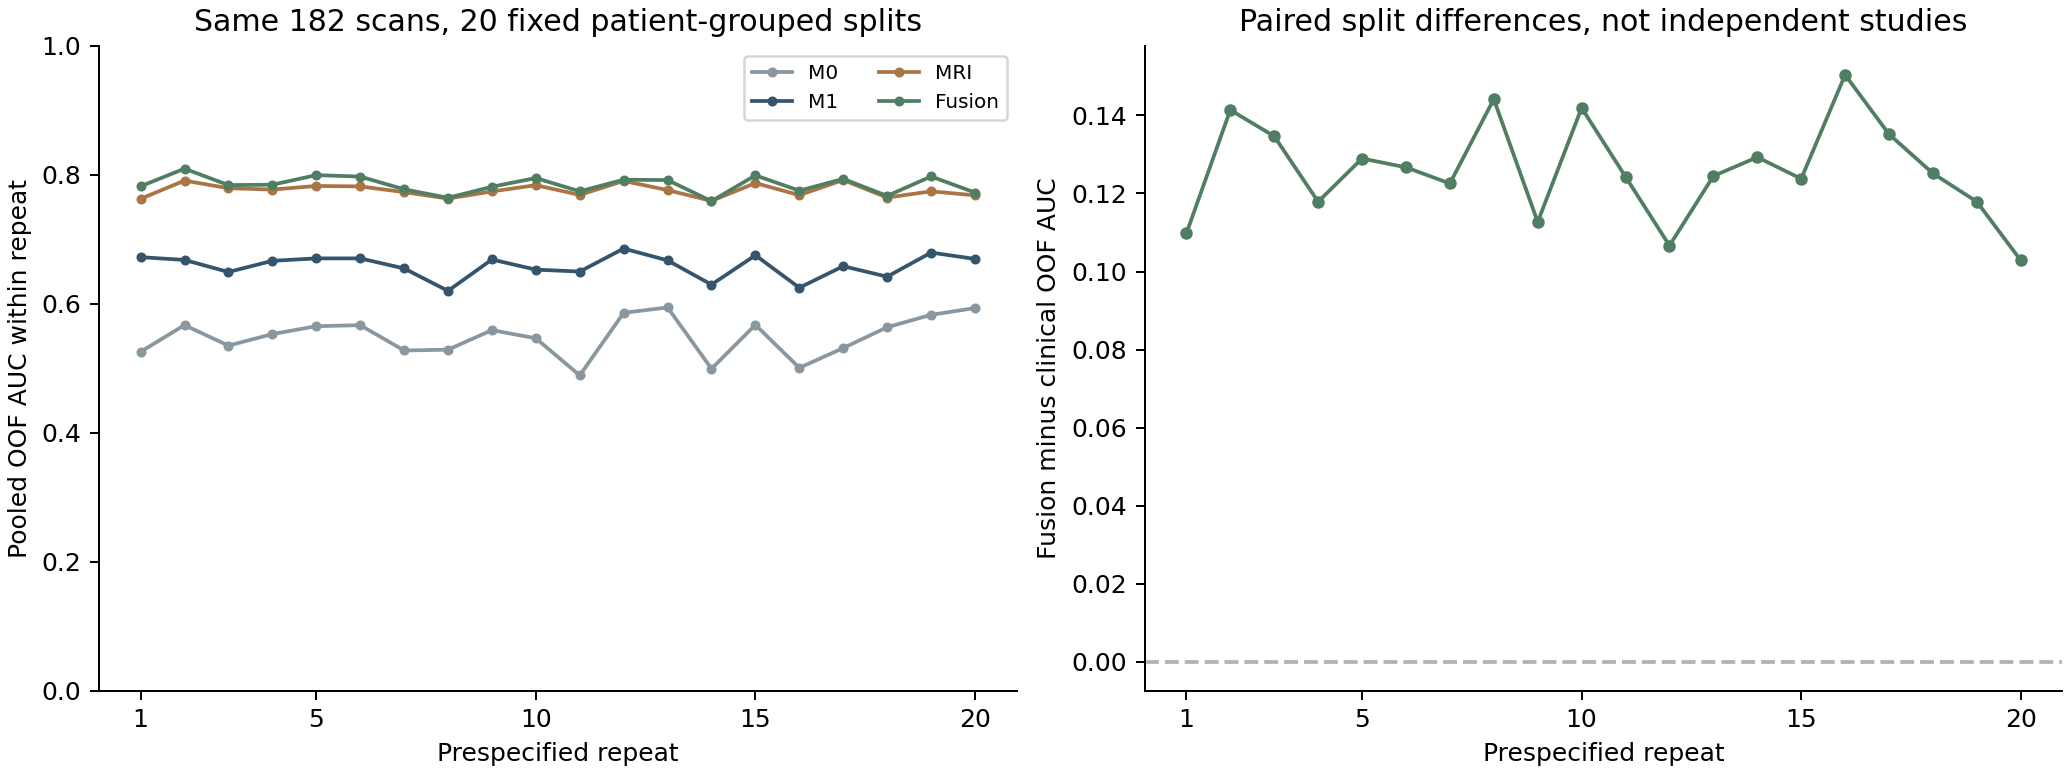

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('stability_deliverables',ROOT/'scripts/make_ucsd_stability_deliverables.py')
module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
module.generate(ROOT)
from IPython.display import display,Image
display(Image(filename=str(ROOT/'figures/ucsd_stability/repeated_validation.png')))
display(Image(filename=str(ROOT/'figures/ucsd_stability/single_scan_sensitivity.png')))

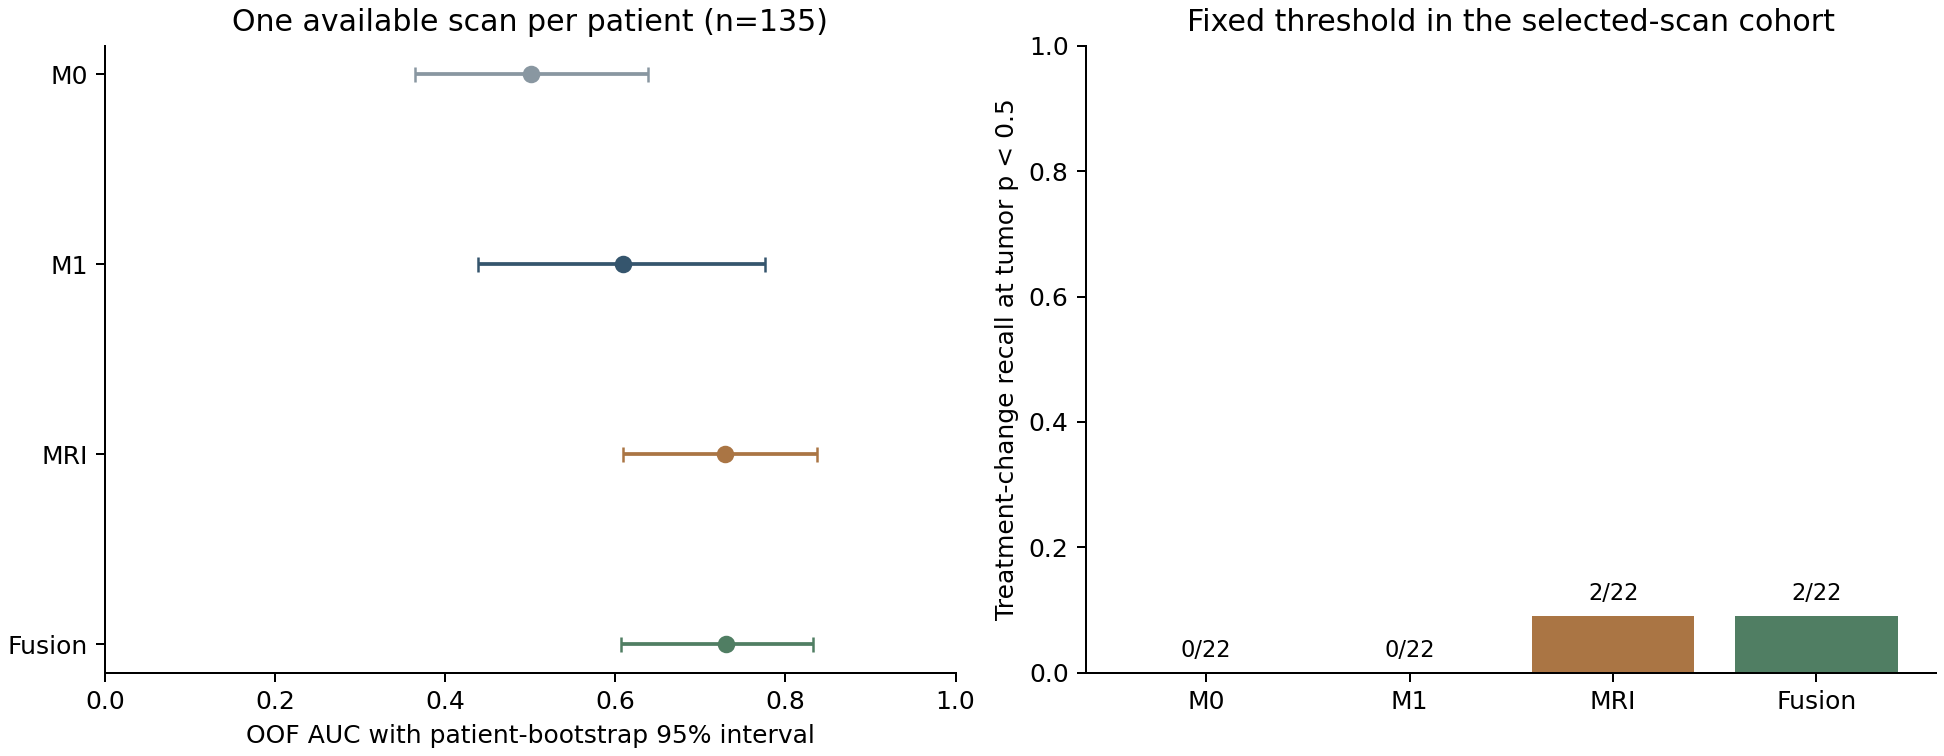

Frozen inputs, code and patient isolation verified; no independent-repeat confidence claim.


In [5]:
import hashlib
for p,h in lock['input_sha256'].items():
    assert hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==h
assert hashlib.sha256((ROOT/'reports/ucsd_stability_protocol.md').read_bytes()).hexdigest()==lock['protocol_sha256']
assert hashlib.sha256((ROOT/'src/rn_public/ucsd_stability.py').read_bytes()).hexdigest()==lock['analysis_code_sha256']
repeated=pd.read_csv(ROOT/'data/processed/ucsd_stability_repeated_oof.csv')
for _,frame in repeated.groupby('repeat'):
    assert frame.ID.is_unique and len(frame)==182
    for key in ['patient_id','brats_patient_id','validation_group']:
        assert frame.groupby(key).validation_fold.nunique().eq(1).all()
assert not summary['prior_primary_analysis_replaced']
print('Frozen inputs, code and patient isolation verified; no independent-repeat confidence claim.')

保留第18步为原主分析。完整结果、失败次数和局限均需报告，不选择最高重复替代主结果。此阶段结束后等待用户批准论文材料整理。